# Lab 09: How to build an agent from LangChain's pieces

**Notebook 2 of 2: LangChain at the Chinook desk**

## Goal

Put LangChain to work on a real job: the support desk of the Chinook music shop, where a rep asks about a customer
and the agent looks the facts up in the shop's database. We build the desk agent with `create_agent` and read its
run. Then one ordinary line of code, `answer.content.lower()`, crashes on the agent's answer, although it works on a
plain model reply, because the agent's `.content` is a list of content blocks and not a string. We ask for the same
answer as a typed record, and see a complete record for a customer the shop does not have. Last, the agent gets a
tool that writes, and LangChain's middleware makes a refund wait for a person, who approves one request and rejects
another.

## What you will learn

- How to build an agent over a database from plain lookup functions with `create_agent`, and read its run message
  by message, with its tokens and its cost.
- Why a reply's `.content` can be a string or a list of content blocks, and how `.text` reads both.
- How to ask an agent for a typed answer with `response_format`, and how to check in code where its facts came
  from.
- How to make a tool call wait for a person with `HumanInTheLoopMiddleware`, read what is waiting, and approve or
  reject it.
- What the checkpointer and the thread id are for in that pause.

## From the playground to the desk

In notebook 1 we met LangChain's pieces on small jobs for a friend. Three names carry over:

- `ChatOpenAI` is the model object. `invoke` sends one request and returns an `AIMessage`.
- A plain Python function with type hints and a docstring can be a tool: LangChain writes the description the
  model reads from the function itself.
- `create_agent(model, tools, system_prompt=...)` returns the loop: call the model, run the tools it asks for, send
  the results back, stop when a reply has no tool call in it.

Now we take it seriously. The tools read a shop's database, a rep will repeat the answers to a customer, and one
tool will write. This notebook restates everything it uses, so it runs on its own.

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model and prices from
`models.env`, and takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import json
import sqlite3
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


One model object for the whole notebook. `reasoning_effort` comes from `models.env`, and `timeout=60` makes a
request that gets stuck fail after 60 seconds instead of freezing a cell.

In [2]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT, timeout=60)

print(type(llm).__name__, "| model:", llm.model_name)

ChatOpenAI | model: gpt-6-luna


---

## Part A: Build the desk agent from three database lookups

The shop's data is `data/chinook.db`, a SQLite file with the customers, their invoices and the support reps who look
after them. A rep at the desk asks things like:

> How many invoices does Helena Holý have, what do they add up to, and who is her support rep?

The question asks for three facts, and they are in three tables. We write one small function for each lookup and
call them ourselves first, so we know the right answers before any model is involved.

### The three lookups

- `find_customer(name)` finds a customer by full name and returns their `customer_id`. It returns a list, because
  two customers could share a name.
- `get_invoices(customer_id)` counts that customer's invoices and adds up their total.
- `get_support_rep(customer_id)` names the rep who looks after them.

Two details in the first lines. `mode=ro` opens the database **read-only**, so no lookup can change the shop's
data. `check_same_thread=False` is needed because the agent runs tools in worker threads, not in the thread that
opened the connection.

Each function has type hints and a docstring, because LangChain builds the tool's description from them.

In [3]:
DB_PATH = ROOT / "data" / "chinook.db"
conn = sqlite3.connect(f"file:{DB_PATH}?mode=ro", uri=True, check_same_thread=False)


def find_customer(name: str) -> list:
    """Find a shop customer by full name. Returns a list of matches with their customer_id."""
    rows = conn.execute(
        "SELECT CustomerId, FirstName || ' ' || LastName, Country FROM customers "
        "WHERE FirstName || ' ' || LastName = ?", (name,)).fetchall()
    return [{"customer_id": r[0], "name": r[1], "country": r[2]} for r in rows]


def get_invoices(customer_id: int) -> dict:
    """Count a customer's invoices and add up their total in US dollars."""
    count, total = conn.execute(
        "SELECT COUNT(*), ROUND(SUM(Total), 2) FROM invoices WHERE CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "invoice_count": count, "total": total}


def get_support_rep(customer_id: int) -> dict:
    """Name the support rep who looks after a customer."""
    row = conn.execute(
        "SELECT e.FirstName || ' ' || e.LastName FROM customers c "
        "JOIN employees e ON e.EmployeeId = c.SupportRepId WHERE c.CustomerId = ?", (customer_id,)).fetchone()
    return {"customer_id": customer_id, "support_rep": row[0] if row else None}

We look up two customers by hand: Helena, and Puja Srivastava, who comes back in Part D.

In [4]:
for name in ["Helena Holý", "Puja Srivastava"]:
    customer = find_customer(name)[0]
    print(customer)
    print("   ", get_invoices(customer["customer_id"]))
    print("   ", get_support_rep(customer["customer_id"]))

{'customer_id': 6, 'name': 'Helena Holý', 'country': 'Czech Republic'}
    {'customer_id': 6, 'invoice_count': 7, 'total': 49.62}
    {'customer_id': 6, 'support_rep': 'Steve Johnson'}
{'customer_id': 59, 'name': 'Puja Srivastava', 'country': 'India'}
    {'customer_id': 59, 'invoice_count': 6, 'total': 36.64}
    {'customer_id': 59, 'support_rep': 'Jane Peacock'}


These are the facts every answer in this notebook is checked against:

| Customer | `customer_id` | Invoices | Total | Support rep |
|---|---|---|---|---|
| Helena Holý | 6 | 7 | \$49.62 | Steve Johnson |
| Puja Srivastava | 59 | 6 | \$36.64 | Jane Peacock |

**Notice** the order the lookups need. `get_invoices` and `get_support_rep` take a `customer_id`, and only
`find_customer` can supply it. Our code does not state that order. The model has to ask for `find_customer` first.

### The desk agent

`create_agent` takes the model, the three functions and a system prompt. The prompt asks for every fact to come
from a lookup: Chinook is a public sample database, and a model may have seen its numbers in training data.

In [5]:
from langchain.agents import create_agent

DESK_TOOLS = [find_customer, get_invoices, get_support_rep]

SYSTEM = ("You help the support reps of a music shop. Look up every fact with the tools; never answer from memory. "
          "Answer in one or two sentences.")

desk = create_agent(llm, DESK_TOOLS, system_prompt=SYSTEM)

print(type(desk).__name__)
print(list(desk.get_graph().nodes))

CompiledStateGraph
['__start__', 'model', 'tools', '__end__']


The agent is a `CompiledStateGraph`: LangChain builds its agents on LangGraph, a library that describes a program
as steps, called **nodes**, and the arrows between them. This one has four nodes. `__start__` and `__end__` are
where a run enters and leaves, `model` calls the model, and `tools` runs our lookups. The library draws it:

(The drawing is made by the mermaid.ink web service, which gets the names of the nodes and the arrows and nothing
else. If the cell fails, see Troubleshooting. Every other cell works without it.)

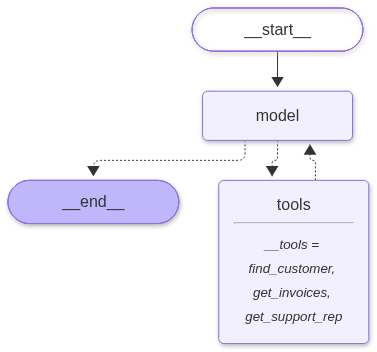

In [6]:
from IPython.display import Image

Image(desk.get_graph().draw_mermaid_png())

The `tools` box lists our three lookups. The solid arrow always runs: every run begins with a model call. The
dotted arrows mean "only if": after a model call the run goes to `tools` if the reply asks for a tool, and to
`__end__` if it does not. The arrow from `tools` back to `model` is the loop. It is dotted because a tool can be
marked to end the run with its own result (`return_direct=True`). Ours are not, so `tools` always goes back to
`model`.

### Run the desk agent and read its messages

The agent's input is a dictionary with one key, `messages`: the conversation so far. We start it with the rep's
question. `invoke` runs the loop and returns the final state, a dictionary of the same shape whose `messages` now
hold the whole run.

When a reply asks for tools, its `tool_calls` is a list of dictionaries, one per request, each with the tool's
`name` and its `args`. `describe` is a small helper for printing. It turns one message into one line: for a reply
that asks for tools, the requests in its `tool_calls`; for anything else, its `text`.

In [7]:
def describe(message):
    """One line that says what a message holds."""
    if message.type == "ai" and message.tool_calls:
        return "asks for " + str([(call["name"], call["args"]) for call in message.tool_calls])
    return message.text


HELENA = "How many invoices does Helena Holý have, what do they add up to, and who is her support rep?"

result = desk.invoke({"messages": [{"role": "user", "content": HELENA}]})

for message in result["messages"]:
    print(f"{message.type:5} | {describe(message)}")

human | How many invoices does Helena Holý have, what do they add up to, and who is her support rep?
ai    | asks for [('find_customer', {'name': 'Helena Holý'})]
tool  | [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
ai    | asks for [('get_invoices', {'customer_id': 6}), ('get_support_rep', {'customer_id': 6})]
tool  | {"customer_id": 6, "invoice_count": 7, "total": 49.62}
tool  | {"customer_id": 6, "support_rep": "Steve Johnson"}
ai    | Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.


Seven messages. Each has a `type`: `human` is the rep's question, `ai` is a reply from the model, and `tool` is the
result of a lookup.

1. The model asks for `find_customer` with Helena's name, because the other two lookups need a `customer_id`.
2. The lookup returns customer 6.
3. The model asks for `get_invoices` and `get_support_rep` in the same reply. Neither depends on the other.
4. Two `tool` messages follow, one result per call.
5. The model writes the answer: *Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.*

The answer agrees with the table. Three `ai` messages means the model was called three times.

### What the run cost

Every `ai` message carries `usage_metadata`: the tokens of the model call that produced it. We add them up over
the run and price them with the input and output prices in `models.env`, which are in US dollars per million
tokens.

In [8]:
ai_messages = [message for message in result["messages"] if message.type == "ai"]
input_tokens = [message.usage_metadata["input_tokens"] for message in ai_messages]
output_tokens = sum(message.usage_metadata["output_tokens"] for message in ai_messages)

PRICE_IN = float(settings["PRICE_INPUT_PER_MILLION"])
PRICE_OUT = float(settings["PRICE_OUTPUT_PER_MILLION"])
cost = (sum(input_tokens) * PRICE_IN + output_tokens * PRICE_OUT) / 1_000_000

print("model calls:          ", len(ai_messages))
print("input tokens per call:", input_tokens, "| total:", sum(input_tokens))
print("output tokens:        ", output_tokens)
print(f"cost: ${cost:.6f}")

model calls:           3
input tokens per call: [166, 224, 335] | total: 725
output tokens:         98
cost: $0.000121


- **model calls:** 3, one per `ai` message.
- **input tokens per call:** 166, 224 and 335. The count grows because every call carries the whole conversation
  so far, with the tool requests and results of the calls before. The model keeps nothing between calls.
- **cost:** \$0.000121 for the run. Small for one question, and worth knowing how to compute before a desk
  answers thousands of questions a day.

**Checkpoint A.** The lookups give Helena 7 invoices, \$49.62 and Steve Johnson, and Puja 6, \$36.64 and Jane
Peacock. The agent has the nodes `['__start__', 'model', 'tools', '__end__']`. It answers Helena's question with
her three facts in three model calls, and the input tokens grow from one call to the next.

---

## Part B: Read the agent's answer, whose `.content` can be a list of blocks

A program does something with an answer: it stores it, searches it, checks it. Suppose ours checks that the answer
names the rep. So far we read the words of a message with `.text`. A message has another field, `.content`, which
holds the reply as the API returned it, and it is tempting to treat it as a string. We try that on two replies: a
plain model call, and the agent's answer.

First the plain call.

In [9]:
plain = llm.invoke("In one sentence, what does a support rep at a music shop do?")

print(plain.content.lower())

a support rep at a music shop helps customers choose and use instruments and gear, answers questions, and resolves purchases or service issues.


It works. `.content` is a string, and `.lower()` is a string method: it returns the text in lower case, which is
what a search for a name wants.

Now the same line on the agent's answer, the last message of Part A's run. Before you run it: what do you expect?

In [10]:
answer = result["messages"][-1]

try:
    print("steve johnson" in answer.content.lower())
except AttributeError as error:
    print("AttributeError:", error)

AttributeError: 'list' object has no attribute 'lower'


`AttributeError: 'list' object has no attribute 'lower'`. The same line that worked on the plain reply crashes
here. (`try` and `except AttributeError` catch the error so that we can print it and carry on; without them the
cell would stop with the same message.)

The error says `.content` is a list this time. We look inside.

In [11]:
print(type(plain.content).__name__, "|", type(answer.content).__name__)
print(len(answer.content), "item")
print(answer.content[0])

str | list
1 item
{'type': 'text', 'text': 'Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.', 'annotations': [], 'id': 'msg_06208345c29ae457006af43d583f7087d2ab0f53394c45d1bc', 'phase': 'final_answer'}


A `str` for the plain reply, a `list` for the agent's answer. The list has one item, a dictionary called a
**content block**:

- `type`: `text`, a block of words. Other types of block hold tool requests or reasoning.
- `text`: the answer itself.
- `annotations`: citations, empty here.
- `id` and `phase`: the API's own label for this piece of output, and its stage, `final_answer`.

**Why is it a list here and a string there?** The two calls went to two different OpenAI APIs. The first
characters of each reply's id show which:

In [12]:
print("plain reply:   ", plain.response_metadata["id"][:9])
print("agent's answer:", answer.response_metadata["id"][:5])

plain reply:    chatcmpl-
agent's answer: resp_


- `chatcmpl-` is the **Chat Completions** API. It returns a reply's words as one string.
- `resp_` is the **Responses** API, OpenAI's newer one. It returns a list of items, and LangChain keeps that list
  as `.content`.

We never chose between them. `ChatOpenAI` chooses for each call: for this model, a request with no tools goes to
Chat Completions, and a request that carries tools goes to Responses. An agent always carries tools.

So `.content` is whatever the provider's API returned, and its type can change with the model, the provider or the
tools. Code that calls string methods on it works on a call with no tools and crashes on a call that carries tools.

### `.text` reads every reply the same way

`.text` joins the text blocks of a message into one string. On a message whose content is already a string, it
returns that string.

In [13]:
print("plain reply:   ", plain.text)
print("agent's answer:", answer.text)
print("names the rep: ", "steve johnson" in answer.text.lower())

plain reply:    A support rep at a music shop helps customers choose and use instruments and gear, answers questions, and resolves purchases or service issues.
agent's answer: Helena Holý has 7 invoices totaling $49.62. Her support rep is Steve Johnson.
names the rep:  True


Both read as strings now, and the check finds the rep's name: `True`.

**Key lesson:** read a reply's words with `.text` and its tool requests with `.tool_calls`. Do not call string
methods on `.content`.

**Checkpoint B.** `.content.lower()` works on the plain reply and gives `AttributeError: 'list' object has no
attribute 'lower'` on the agent's answer. The answer's content is a list with one block of type `text`. The ids
start with `chatcmpl-` and `resp_`. With `.text` the check prints `True`.

---

## Part C: Ask for a typed answer, and check where its facts came from

The answer is a sentence. Code that stores it in a table, or adds up totals, would have to pick numbers out of
words. A **typed answer** is an object with named fields. Here is the one we want for Helena, written by hand from
the lookups in Part A:

In [14]:
wanted = {"customer_name": "Helena Holý", "invoice_count": 7, "total_usd": 49.62, "support_rep": "Steve Johnson"}
print(wanted)

{'customer_name': 'Helena Holý', 'invoice_count': 7, 'total_usd': 49.62, 'support_rep': 'Steve Johnson'}


Four fields: two strings, a whole number and a decimal number. We describe that shape as a **Pydantic model**, a
class that lists each field with its type. `Field(description=...)` adds a sentence the model reads, so a
description is an instruction and not a comment.

In [15]:
from pydantic import BaseModel, Field


class DeskAnswer(BaseModel):
    """The facts a support rep asked for about one customer."""
    customer_name: str = Field(description="The customer's full name, as the database spells it")
    invoice_count: int
    total_usd: float = Field(description="What the customer's invoices add up to, in US dollars")
    support_rep: str

`create_agent(..., response_format=DeskAnswer)` adds the class to the agent. The loop runs as before, and the
model's last reply must fit the class. LangChain reads that reply into a `DeskAnswer` and puts it in the state
under a second key, `structured_response`.

In [16]:
typed_desk = create_agent(llm, DESK_TOOLS, system_prompt=SYSTEM, response_format=DeskAnswer)

typed = typed_desk.invoke({"messages": [{"role": "user", "content": HELENA}]})

record = typed["structured_response"]
print(list(typed))
print(repr(record))
print(f"average invoice: ${record.total_usd / record.invoice_count:.2f}")

['messages', 'structured_response']
DeskAnswer(customer_name='Helena Holý', invoice_count=7, total_usd=49.62, support_rep='Steve Johnson')
average invoice: $7.09


The state has a second key now, `structured_response`. It holds a `DeskAnswer` whose four fields match the entry
we wanted. Python reads the fields as attributes, so `record.total_usd / record.invoice_count` is ordinary
arithmetic: 49.62 divided by 7 is \$7.09.

### What does the type not check?

The class checks the shape: every field present, each of the right type. To see what it leaves out, we ask about a
customer the database cannot find. A rep in a hurry types Helena's surname without its accent, *Holy* for *Holý*.
`find_customer` matches the full name exactly:

In [17]:
print(find_customer("Helena Holy"))

[]


An empty list: the shop has no customer spelled that way. The correct answer to the rep's question is "I
cannot find that customer".

Before you run the next cell: `DeskAnswer` has four required fields and no place for "not found". What will the
typed agent return?

The cell prints the record, then the run's messages without the last one: the last message is the record again,
as JSON text.

In [18]:
miss = typed_desk.invoke({"messages": [{"role": "user", "content": HELENA.replace("Holý", "Holy")}]})

print(repr(miss["structured_response"]))
print()
for message in miss["messages"][:-1]:
    print(f"{message.type:5} | {describe(message)}")

DeskAnswer(customer_name='Helena Holy', invoice_count=0, total_usd=0.0, support_rep='None')

human | How many invoices does Helena Holy have, what do they add up to, and who is her support rep?
ai    | asks for [('find_customer', {'name': 'Helena Holy'})]
tool  | 
ai    | asks for [('get_invoices', {'customer_id': 62})]
tool  | {"customer_id": 62, "invoice_count": 0, "total": null}
ai    | asks for [('get_support_rep', {'customer_id': 62})]
tool  | {"customer_id": 62, "support_rep": null}


A complete `DeskAnswer`, with all four fields filled: 0 invoices, a total of 0.0, and the rep *None*.
Nothing in it says that the customer was not found. A rep who reads this record tells the customer she has never
bought anything, and Helena has 7 invoices.

The messages under the record show where its values came from:

1. The agent asked for `find_customer` with *Helena Holy*.
2. The `tool` line after it is empty: the lookup found nobody.
3. The agent still asked for `get_invoices`, with `customer_id` 62. No tool returned 62. The model made
   the number up.
4. The shop has no customer 62, so the two lookups returned a count of 0 and no rep, and the model wrote those
   into the record.

The run raised no error, and the record passed the type's check. In most of our other runs of this cell the
invented id belonged to a real customer, and the record held that customer's invoices and rep under the name
*Helena Holy*.

### Check the source in code

The type cannot tell us where a number came from. The messages can: every tool result is in the run. The rule we
need is short: use the record only if `find_customer` found someone.

`customer_found` reads a run's messages. A tool's result is a message of type `tool`. Its `name` is the tool that
ran, and its `text` is what the function returned, as text. We collect the text of every `find_customer` result,
and say "found" when one of them is not empty.

In [19]:
def customer_found(run):
    """True when a find_customer call in this run returned a match."""
    results = [message.text for message in run["messages"]
               if message.type == "tool" and message.name == "find_customer"]
    print("find_customer returned:", results)
    return any(text not in ("", "[]") for text in results)


print("Helena Holý:", customer_found(typed))
print()
print("Helena Holy:", customer_found(miss))

find_customer returned: ['[{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]']
Helena Holý: True

find_customer returned: ['']
Helena Holy: False


For the name with its accent, `find_customer` returned one match, and `customer_found` is `True`. For the name
without it, the result's text is the empty string `''`, and `customer_found` is `False`. One function of ours,
reading what the tool returned, separates the record we can use from the one we cannot.

It checks one thing: that the customer was found. It does not compare the numbers in the record with the tool
results. A stricter check would also read the `get_invoices` result and the `customer_id` it was called with.

**Why did the agent carry on?** Look at what it was told. A lookup that finds Helena returns a list with one
dictionary, and LangChain sends it to the model as text. A lookup that finds nobody returns an empty Python list,
and LangChain sends the model an empty result: no text at all, not even `[]`. The model was never told "no match".
It was told nothing, and it made up a `customer_id`.

**In production:** make a lookup say what happened in words (*No customer is called Helena Holy.*), and give the
type a place for "not found". The Challenge builds both.

**Key lesson:** a typed answer is always complete, because the type demands it. That makes it easy to store and
easy to trust too much. The type checks the shape. Where the values came from is for our code to check, against
what the tools returned.

**Checkpoint C.** The typed agent returns `DeskAnswer(customer_name='Helena Holý', invoice_count=7,
total_usd=49.62, support_rep='Steve Johnson')` and an average invoice of \$7.09. For *Helena Holy*, `find_customer`
returns `[]` and the agent still returns a complete `DeskAnswer`. Ours holds 0 invoices, a total of 0.0 and the rep *None*, after a
`get_invoices` call with a `customer_id` that no tool returned; on other runs it held another customer's numbers.
`customer_found` gives `True` for the first run and `False` for the second.

---

## Part D: Make a refund wait for a person

So far the agent only reads. Filing a refund request is a write: once it has run, something has changed outside
the conversation. This part gives the agent a tool that writes, and then makes that tool wait for a person.

### A tool that writes

`file_refund_request` adds one request to the shop's list of refund requests. Our stand-in for that system is a
Python list, `REFUND_REQUESTS`, so we can print what it holds after every step.

In [20]:
REFUND_REQUESTS = []


def file_refund_request(invoice_id: int, amount: float, reason: str) -> str:
    """File a refund request for one invoice, in US dollars. A person reviews it before any money moves."""
    REFUND_REQUESTS.append({"invoice_id": invoice_id, "amount": amount, "reason": reason})
    return f"refund request {len(REFUND_REQUESTS)} filed: invoice {invoice_id}, {amount} US dollars"

### The agent files a refund with nobody watching

First the agent as we have built it so far, with the new tool added. A rep sends a request:

In [21]:
REQUEST = ("Helena Holý was charged twice for invoice 393 (1.98 US dollars). "
           "Please file a refund request for the duplicate charge.")

quick_desk = create_agent(llm, DESK_TOOLS + [file_refund_request], system_prompt=SYSTEM)

done = quick_desk.invoke({"messages": [{"role": "user", "content": REQUEST}]})

for message in done["messages"]:
    print(f"{message.type:5} | {describe(message)}")
print()
print("refund requests:", REFUND_REQUESTS)

human | Helena Holý was charged twice for invoice 393 (1.98 US dollars). Please file a refund request for the duplicate charge.
ai    | asks for [('find_customer', {'name': 'Helena Holý'})]
tool  | [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
ai    | asks for [('get_invoices', {'customer_id': 6})]
tool  | {"customer_id": 6, "invoice_count": 7, "total": 49.62}
ai    | asks for [('file_refund_request', {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge for invoice 393.'})]
tool  | refund request 1 filed: invoice 393, 1.98 US dollars
ai    | I filed a refund request for $1.98 for the duplicate charge on invoice 393. A person will review it before any money is refunded.

refund requests: [{'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge for invoice 393.'}]


The agent looked Helena up, counted her invoices, then asked for `file_refund_request` with invoice 393 and 1.98,
the numbers in the rep's message, and a reason it wrote itself. The tool ran at once: the list holds one request,
and the reply says it is filed.

Nobody checked anything. The model did not check that invoice 393 is Helena's, or that its total is 1.98: it has
no tool that reads an invoice. And no person saw the request before it was written.

We empty the list and start again, more carefully.

In [22]:
REFUND_REQUESTS.clear()
print("refund requests:", REFUND_REQUESTS)

refund requests: []


### Stop before the write with `HumanInTheLoopMiddleware`

**Middleware** is how LangChain adds a step to `create_agent`'s loop without rewriting the loop: an object whose
code runs at a fixed point, such as before a tool runs. `HumanInTheLoopMiddleware` stops the run when the model
asks for a tool we name, and hands the waiting request to our code. Nothing has run yet. We answer with a
decision, and the run continues from where it stopped.

- `interrupt_on` names the tool to stop on, and the decisions a reviewer may send. `approve` runs the call as it
  is, `reject` runs nothing and tells the model why, and `edit` runs a corrected call (the Challenge uses it). The
  three lookups are not named, so they run without stopping.
- `interrupt_mode="per_call"` stops once for each call that needs review. It is the mode LangChain's documentation
  recommends for new agents. The default mode, `batched`, stops once per model reply and lists every call of that
  reply that needs review.

A run that stops has to be kept somewhere until the person answers, which may be minutes later, in another cell.
The agent needs two more things for that:

- a **checkpointer**: the place where the paused run is kept. `InMemorySaver` keeps it in this notebook's memory.
- a **thread id**: a name for the conversation, passed with every call in `config`. It says which paused run our
  decision belongs to.

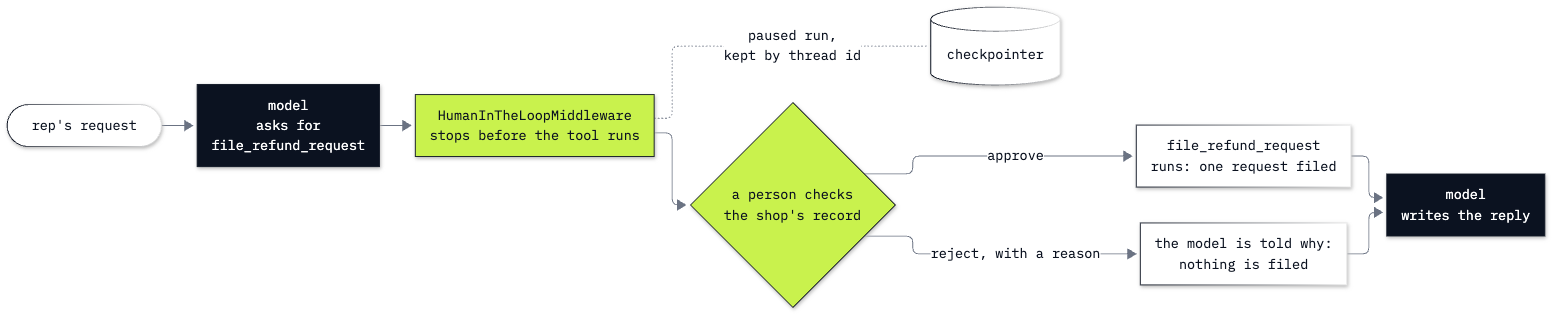

In [23]:
Image("resources/lab09_refund_approval.png", width=760)

The dark boxes are the model, and lime marks the two steps this part adds: the stop, and the person's decision.

In [24]:
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver

approval = HumanInTheLoopMiddleware(
    interrupt_on={"file_refund_request": {"allowed_decisions": ["approve", "edit", "reject"]}},
    interrupt_mode="per_call",
)

careful_desk = create_agent(
    llm,
    DESK_TOOLS + [file_refund_request],
    system_prompt=SYSTEM,
    middleware=[approval],
    checkpointer=InMemorySaver(),
)

The same request again, on a thread we name `refund-helena`. `version="v2"` makes `invoke` return an object with
two parts: `.value`, the state (the messages), and `.interrupts`, what is waiting for a decision. Without it, `invoke`
returns a plain dictionary, with what is waiting under the key `__interrupt__`.

In [25]:
config = {"configurable": {"thread_id": "refund-helena"}}

paused = careful_desk.invoke({"messages": [{"role": "user", "content": REQUEST}]}, config, version="v2")

for message in paused.value["messages"]:
    print(f"{message.type:5} | {describe(message)}")
print()
print("waiting for a decision:", len(paused.interrupts))
print("refund requests:", REFUND_REQUESTS)

human | Helena Holý was charged twice for invoice 393 (1.98 US dollars). Please file a refund request for the duplicate charge.
ai    | asks for [('find_customer', {'name': 'Helena Holý'})]
tool  | [{"customer_id": 6, "name": "Helena Holý", "country": "Czech Republic"}]
ai    | asks for [('get_invoices', {'customer_id': 6})]
tool  | {"customer_id": 6, "invoice_count": 7, "total": 49.62}
ai    | asks for [('file_refund_request', {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge for invoice 393.'})]

waiting for a decision: 1
refund requests: []


The run begins as before: the agent looks Helena up, counts her invoices and asks for `file_refund_request`. Then
it stops. No `tool` message follows the request, one decision
is waiting, and the list is empty: nothing was written.

What is waiting? Each interrupt has a `value` that describes the call, and an `id` we will need for the answer.

In [26]:
waiting = paused.interrupts[0]

print(json.dumps(waiting.value, indent=2, ensure_ascii=False))
print("interrupt id:", waiting.id)

{
  "type": "tool_approval",
  "tool_call_id": "call_zy0w4lZgiIlCbmJhYlSZpjAo",
  "name": "file_refund_request",
  "args": {
    "invoice_id": 393,
    "amount": 1.98,
    "reason": "Duplicate charge for invoice 393."
  },
  "description": "Tool execution requires approval\n\nTool: file_refund_request\nArgs: {'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge for invoice 393.'}"
}
interrupt id: 749299a384849bb5d0ce4bf81d6a2ca1


The fields a reviewer needs:

- `name` and `args`: the call that is waiting. It is `file_refund_request` for invoice 393 and 1.98 US dollars,
  with the reason *Duplicate charge for invoice 393.*
- `description`: the same call as a few lines of text, ready for a review screen.
- `type` says that a tool is waiting for approval, and `tool_call_id` is the model's label for its request.

The last line is the interrupt's own `id`. It is not the `tool_call_id`: it names the pause, and it is the key we
use to answer.

### The person checks the record, then approves

A reviewer does not approve from the request alone. They check it against the shop's records. `show_invoice` is
the reviewer's own lookup: it reads one invoice with the name of the customer it belongs to. The agent does not
have it.

In [27]:
def show_invoice(invoice_id):
    """Print one invoice from the shop's database: its number, customer, date and total."""
    row = conn.execute(
        "SELECT i.InvoiceId, c.FirstName || ' ' || c.LastName, date(i.InvoiceDate), i.Total "
        "FROM invoices i JOIN customers c ON c.CustomerId = i.CustomerId WHERE i.InvoiceId = ?",
        (invoice_id,)).fetchone()
    print("the shop's record:", row)


show_invoice(393)

the shop's record: (393, 'Helena Holý', '2013-10-03', 1.98)


Invoice 393 belongs to Helena Holý and its total is 1.98. The request is for the right customer, invoice and
amount.

To approve, we call the agent again on the **same thread**, with a `Command` instead of a message. Its `resume`
value is a dictionary from the interrupt's `id` to our decision.

In [28]:
from langgraph.types import Command

approved = careful_desk.invoke(Command(resume={waiting.id: {"type": "approve"}}), config, version="v2")

for message in approved.value["messages"][-2:]:
    print(f"{message.type:5} | {describe(message)}")
print()
print("waiting for a decision:", len(approved.interrupts))
print("refund requests:", REFUND_REQUESTS)

tool  | refund request 1 filed: invoice 393, 1.98 US dollars
ai    | I filed a refund request for $1.98 for the duplicate charge on invoice 393. A person will review it before any money is refunded.

waiting for a decision: 0
refund requests: [{'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge for invoice 393.'}]


The run continued from where it stopped. The tool ran with the arguments the reviewer saw (`refund request 1
filed`), the model wrote its reply, nothing is waiting, and the list holds one request.

### A request the person rejects

A second rep sends a request about another customer, on a thread of its own:

In [29]:
REQUEST_2 = ("Puja Srivastava was charged twice for invoice 175 (1.98 US dollars). "
             "Please file a refund request for the duplicate charge.")
config_2 = {"configurable": {"thread_id": "refund-puja"}}

paused_2 = careful_desk.invoke({"messages": [{"role": "user", "content": REQUEST_2}]}, config_2, version="v2")

for message in paused_2.value["messages"]:
    print(f"{message.type:5} | {describe(message)}")
print()
waiting_2 = paused_2.interrupts[0]
print("waiting:", waiting_2.value["name"], waiting_2.value["args"])

human | Puja Srivastava was charged twice for invoice 175 (1.98 US dollars). Please file a refund request for the duplicate charge.
ai    | asks for [('find_customer', {'name': 'Puja Srivastava'})]
tool  | [{"customer_id": 59, "name": "Puja Srivastava", "country": "India"}]
ai    | asks for [('file_refund_request', {'invoice_id': 175, 'amount': 1.98, 'reason': 'Duplicate charge'})]

waiting: file_refund_request {'invoice_id': 175, 'amount': 1.98, 'reason': 'Duplicate charge'}


The run is on a new thread, `refund-puja`, so it starts from Puja's request alone: none of the messages of
Helena's thread are in it. The agent found Puja, asked for `file_refund_request` with invoice 175 and 1.98, as the
request said, and stopped.

The reviewer checks the record:

In [30]:
show_invoice(175)

the shop's record: (175, 'Helena Holý', '2011-02-15', 1.98)


Invoice 175 is Helena Holý's, not Puja Srivastava's. The rep typed the wrong invoice number or the wrong
customer, and the agent could not check it: none of its lookups reads a single invoice.

We reject, with a `message` for the model that says why.

In [31]:
decision = {
    "type": "reject",
    "message": "Invoice 175 belongs to another customer, not Puja Srivastava. "
               "Do not file it; ask the rep to check the invoice number.",
}

rejected = careful_desk.invoke(Command(resume={waiting_2.id: decision}), config_2, version="v2")

tool_message = rejected.value["messages"][-2]
print("tool message status:", tool_message.status)
print("tool message:       ", tool_message.text)
print()
print("reply:", rejected.value["messages"][-1].text)
print()
print("refund requests:", REFUND_REQUESTS)

tool message status: error
tool message:        User rejected the tool call for `file_refund_request` with reason: Invoice 175 belongs to another customer, not Puja Srivastava. Do not file it; ask the rep to check the invoice number.

reply: I couldn’t file the refund: invoice 175 belongs to someone else, not Puja Srivastava. Please check the invoice number.

refund requests: [{'invoice_id': 393, 'amount': 1.98, 'reason': 'Duplicate charge for invoice 393.'}]


The tool did not run. In its place the model received a `tool` message with the status `error`: *User rejected
the tool call for `file_refund_request` with reason:* followed by our message. The model's reply passes that on to
the rep: *I couldn’t file the refund: invoice 175 belongs to someone else, not Puja Srivastava. Please check the
invoice number.* The list still holds one request, Helena's.

**Key lesson:** the model proposed what each request asked for, both times. It could not tell the good request
from the bad one, because it had no tool that reads an invoice. The person's check against the record told them
apart, and the middleware is what gave the person the chance to make it: the write waited.

Both paused runs were kept by `InMemorySaver`, in this notebook's memory, and each was answered a few cells later
in the same session. What happens to a paused run when the program restarts before the person answers is the
subject of Lab 10.

**Checkpoint D.** Without the middleware the refund is filed at once: one request in the list. With it, the run
stops with one interrupt for `file_refund_request` (invoice 393, 1.98) and the list is empty. After `approve`, the
list holds one request. The second request stops the same way; after `reject`, the tool message has the status
`error`, the reply tells the rep the request was not filed, and the list still holds one request.

---

## In production

- **Keep paused runs somewhere that lasts.** `InMemorySaver` loses every paused run when the program stops. A
  deployed agent keeps them in a database; Lab 10 shows what goes wrong without one.
- **Give the agent the lookup the reviewer used.** With a tool that reads one invoice, the agent could have caught
  the wrong invoice itself. Keep the person for the write anyway: the lookup lowers the number of bad requests,
  and the approval decides what is written.
- **A tool's result is text for the model, so make an empty result say so.** In Part C an empty list reached the
  model as nothing, and the model invented a `customer_id`. Return a sentence for "no match", and check in code
  where each fact came from, as `customer_found` did.
- **Show the waiting call on a review screen.** The interrupt's `value` holds what that screen would show: the tool,
  its arguments and a description.

## What you can do now

- Build an agent over a database with `create_agent`, draw it, and read its run message by message with its
  tokens and cost (Part A).
- Read any reply's words with `.text`, and say why `.content` can be a string or a list of content blocks
  (Part B).
- Ask an agent for a typed answer with `response_format`, and check in code that its facts came from the tools
  (Part C).
- Make a tool call wait for a person with `HumanInTheLoopMiddleware`, read the interrupt, and approve or reject it
  with `Command` on the same thread (Part D).
- Say what the checkpointer and the thread id do in that pause (Part D).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `AttributeError: 'list' object has no attribute 'lower'` | a string method was called on `.content`, which is a list of blocks for this reply | read the words with `.text` |
| `ValueError: Failed to reach https://mermaid.ink API while trying to render your graph ...` | the drawing cell could not reach the web service that makes the picture | run `print(desk.get_graph().draw_mermaid())` to see the same graph as text; every other cell works without the drawing |
| `RuntimeError: Cannot use Command(resume=...) without checkpointer` | the agent was created without `checkpointer=`, so the paused run was not kept | pass `checkpointer=InMemorySaver()` to `create_agent` and send the request again |
| a `tool` line with nothing after it when a run is printed | the tool returned an empty list, which reaches the model as an empty result | make the tool return a sentence for "no match" (Challenge task 1) |
| `IndexError: tuple index out of range` at `paused.interrupts[0]` | the run did not stop: the model answered without asking for `file_refund_request` | print `paused.value["messages"][-1].text` to read what it said, then run the request cell again |
| `sqlite3.OperationalError: unable to open database file` | `data/chinook.db` is missing from the repository folder | restore the file (clone the repository again, or `git checkout data/chinook.db`) |

## Challenge

1. **A typed answer that can say "not found".** Write `find_customer_clearly(name)`, which calls `find_customer`
   and returns its list when there is a match, and the sentence *No customer is called NAME.* when there is none.
   Copy `DeskAnswer` into a new class, `CheckedAnswer`, with one more field, `found: bool`, whose description says
   it is true only when the customer lookup returned a match. Build a typed agent from the new lookup, the other
   two lookups and the new class, and ask Helena's question with both spellings. Expected: for *Helena Holy*,
   `found=False`, one tool call, and empty or zero values in the other fields (no lookup with a made-up
   `customer_id`); for *Helena Holý*, `found=True` with 7 invoices, a total of 49.62 and the rep Steve Johnson.
2. **Edit a refund before it is filed.** Send `careful_desk` this request on a new thread: *Puja Srivastava was
   charged twice for invoice 229. Please file a refund request for 18.36 US dollars.* When it stops, check invoice
   229 with `show_invoice`: the total is 13.86, so the rep swapped two digits. Resume with an `edit` decision,
   `{"type": "edit", "edited_action": {"name": "file_refund_request", "args": {...}}}`, that keeps the model's
   arguments and corrects the amount. Print the reply and `REFUND_REQUESTS`. Expected: the waiting call asks for
   18.36; after the edit the list holds a request for invoice 229 with the amount 13.86, and the reply names
   13.86.

The worked solution, run with its outputs, is in `solved/09b_langchain_at_the_desk_solution.ipynb`.

## Going further

- **More middleware.** `create_agent` comes with others, added the same way in the `middleware` list: a limit on
  model calls, a summary of a long conversation, a retry for a tool that fails.
- **Watch the desk agent step by step.** `desk.stream(..., stream_mode="updates")` hands back each node's messages
  as it finishes, as notebook 1 did for the birthday agent.
- **Trace the agent.** LangSmith, LangChain's hosted tracing service, records every model and tool call of a run
  on a web page. It needs an account; bonus lab B7 uses it on this desk.

## Resources

- [Agents](https://docs.langchain.com/oss/python/langchain/agents): `create_agent`, its loop, tools, system prompt
  and middleware
- [Messages](https://docs.langchain.com/oss/python/langchain/messages): message objects, `.text` and content blocks
- [ChatOpenAI](https://docs.langchain.com/oss/python/integrations/chat/openai): the OpenAI model class, and when it
  uses the Responses API
- [Structured output](https://docs.langchain.com/oss/python/langchain/structured-output): `response_format` on an
  agent
- [Human-in-the-loop](https://docs.langchain.com/oss/python/langchain/human-in-the-loop): the middleware, its
  decisions and the two interrupt modes
- [Built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): the other middleware
  `create_agent` can use
- [OpenAI: Responses API](https://developers.openai.com/api/docs/guides/migrate-to-responses): how it differs from
  Chat Completions

Back to [notebook 1](09a_meet_langchain.ipynb). Next:
[Lab 10: How to draw, pause and resume an agent with LangGraph](../10_LangGraph/README.md).